In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data = {}
for f in sorted(Path("data_clean").glob("*.csv")):
    data[f.stem] = pd.read_csv(f)

windows = pd.read_csv("data_features/windows_5m.csv")
windows = windows[windows["label"] != "left out"].copy()

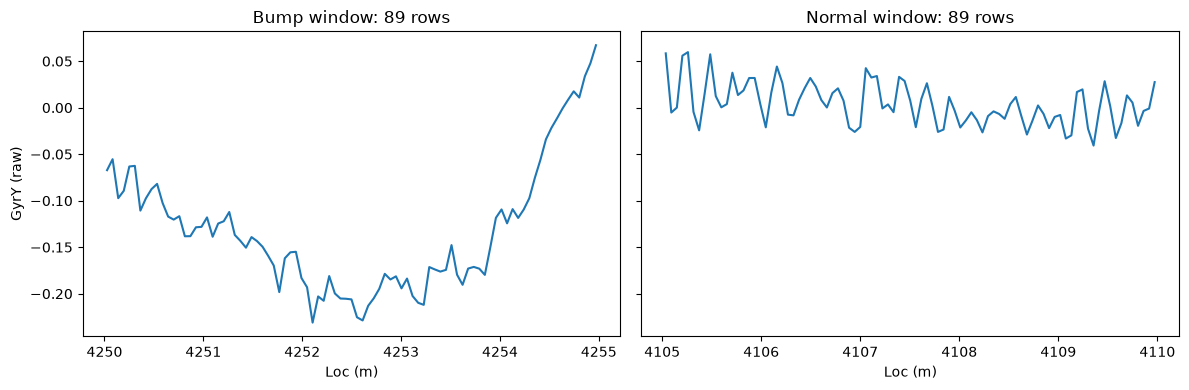

In [ ]:
# Let's visualize the raw GyrY data for a bump window and a normal window
d = data["Iisingintie_Acc1_m800_RDMC_2026-05-06_123750"].copy()
d["window"] = (d["Loc(m)"] // 5).astype(int)

m800 = windows[windows["drive"].str.contains("m800")]
bump_w = m800[m800["label"] == "bump"]["window"].iloc[5]
normal_w = m800[m800["label"] == "no bump"]["window"].iloc[50]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, w_num, title in zip(axes, [bump_w, normal_w], ["Bump window", "Normal window"]):
    rows = d[d["window"] == w_num]
    ax.plot(rows["Loc(m)"], rows["GyrY"])
    ax.set_title(f"{title}: {len(rows)} rows")
    ax.set_xlabel("Loc (m)")
axes[0].set_ylabel("GyrY (raw)")
plt.tight_layout()
plt.show()

#### Now, two problems needs to be solved

* Different lengths. This window has about 90 rows, and at 40 km/h the same 5 m has about 170. But MiniRocket and the CNN need every window to be exactly the same length, like photos that all need the same number of pixels.

* Different scales. At 80 km/h, everything shakes more than at 40 km/h. It’s the same speed problem we solved with relative features, now for the raw signal.

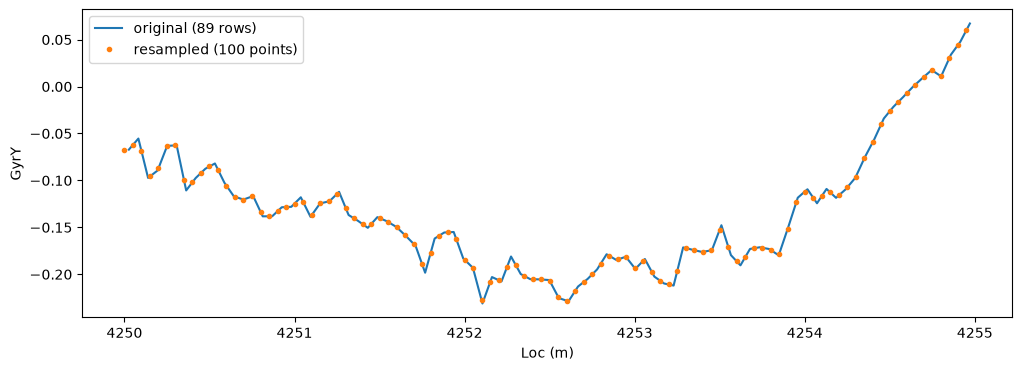

In [ ]:
# Resample one bump window to 100 points
rows = d[d["window"] == bump_w]

# Take the wind
start = bump_w * 5
positions = start + np.arange(100) * 0.05

# Resample the GyrY values to 100 points using linear interpolation
resampled = np.interp(positions, rows["Loc(m)"], rows["GyrY"])

plt.figure(figsize=(12, 4))
plt.plot(rows["Loc(m)"], rows["GyrY"], label=f"original ({len(rows)} rows)")
plt.plot(positions, resampled, "o", markersize=3, label="resampled (100 points)")
plt.xlabel("Loc (m)")
plt.ylabel("GyrY")
plt.legend()
plt.show()

In [4]:
SENSORS = ["GyrY", "AccZ", "GyrX", "GyrZ", "AccY", "AccX", "Pitch(deg)"]
N_POINTS = 100

all_windows = []
index_rows = []

for drive, wins in windows.groupby("drive"):
    d = data[drive].copy()
    d["window"] = (d["Loc(m)"] // 5).astype(int)

    # Normalize each sensor for this drive
    for s in SENSORS:
        name = s.split("(")[0]
        calm_level = wins[name + "_std"].quantile(0.25)
        d[s] = (d[s] - d[s].median()) / calm_level

    # Resample each window of this drive to 100 points
    for _, w in wins.iterrows():
        rows = d[d["window"] == w["window"]]
        positions = w["window"] * 5 + np.arange(N_POINTS) * 0.05

        one_window = []
        for s in SENSORS:
            one_window.append(np.interp(positions, rows["Loc(m)"], rows[s]))

        all_windows.append(one_window)
        index_rows.append({
            "drive": drive,
            "road": w["road"],
            "window": w["window"],
            "is_bump": int(w["label"] == "bump"),
        })

X_raw = np.array(all_windows)
raw_index = pd.DataFrame(index_rows)

print("Shape:", X_raw.shape)

Shape: (2721, 7, 100)


Missing values: 0
Bump windows: 518 | no bump: 2203


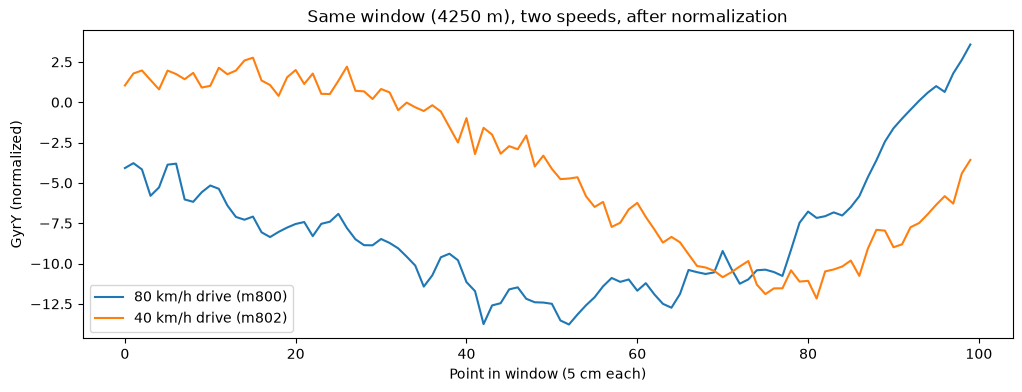

In [5]:
print("Missing values:", np.isnan(X_raw).sum())
print("Bump windows:", raw_index["is_bump"].sum(), "| no bump:", (raw_index["is_bump"] == 0).sum())

i_fast = raw_index[(raw_index["drive"].str.contains("m800")) & (raw_index["window"] == bump_w)].index[0]
i_slow = raw_index[(raw_index["drive"].str.contains("m802")) & (raw_index["window"] == bump_w)].index[0]

plt.figure(figsize=(12, 4))
plt.plot(X_raw[i_fast, 0], label="80 km/h drive (m800)")
plt.plot(X_raw[i_slow, 0], label="40 km/h drive (m802)")
plt.xlabel("Point in window (5 cm each)")
plt.ylabel("GyrY (normalized)")
plt.title(f"Same window ({bump_w * 5} m), two speeds, after normalization")
plt.legend()
plt.show()

In [6]:
rows_fast = data["Iisingintie_Acc1_m800_RDMC_2026-05-06_123750"]
rows_slow = data["Iisingintie_Acc1_m802_RDMC_2026-05-06_125211"]

raw_fast = rows_fast[(rows_fast["Loc(m)"] // 5) == bump_w]["GyrY"].std()
raw_slow = rows_slow[(rows_slow["Loc(m)"] // 5) == bump_w]["GyrY"].std()

print("Before normalization: fast", round(raw_fast, 4), "| slow", round(raw_slow, 4),
      "| ratio", round(raw_fast / raw_slow, 1))
print("After normalization:  fast", round(X_raw[i_fast, 0].std(), 2), "| slow", round(X_raw[i_slow, 0].std(), 2),
      "| ratio", round(X_raw[i_fast, 0].std() / X_raw[i_slow, 0].std(), 1))

Before normalization: fast 0.0678 | slow 0.0644 | ratio 1.1
After normalization:  fast 3.96 | slow 4.79 | ratio 0.8


In [7]:
np.save("data_features/raw_windows_5m.npy", X_raw)
raw_index.to_csv("data_features/raw_windows_index.csv", index=False)

## Conclusions

- Every window from the window table (2,721, same windows and labels as the random forest: 518 bump, 2,203 no bump) was turned into a raw-signal input of 7 sensors × 100 points.
- Resampling: each 5 m window is interpolated to 100 points spaced 5 cm apart by distance, so every window has the same length regardless of speed (originally 39–171 rows).
- Normalization per drive and sensor: subtract the drive's median, divide by its calm level (25th percentile of window std, the same as for the relative features). Uses sensor data only, no labels.
- Check: same window at 80 and 40 km/h. Shaking about 4× vs 5× the drive's calm level after normalization, so both clearly stand out. The exact wiggles differ (different drives, small position shifts, speed changes the bounce rhythm), but the overall trend matches.
- Saved: `data_features/raw_windows_5m.npy` (signal) and `data_features/raw_windows_index.csv` (which window each one is).